# Figure 6: the signal is spread over many TSSs and reflects the cellular origin of cfDNA

Re-plots source data of the supplementary analyses (no_deep cohort); no analysis of its own.

| panel | what is drawn | source data (`data/no_deep/`) | exporter |
|---|---|---|---|
| a | each cancer type against the six other types pooled | `figS_loco_consistency_summary.json`, `figS_loco_consistency_matrix.csv`, `figS_loco_consistency_bootstrap.csv` | `export/export_figS_loco_consistency.py`, `export/export_figS_loco_consistency_boot.py` |
| b | cell-type signatures (MSigDB C8) that differ from look-alike TSSs, by class and direction | `figS18_gsea_matched_10k.csv`, `figS18_c8_classes.csv` | `export/export_figS18_matched_10k.py` |

Panel a also reads `fig4_loco_per_type.csv` (bar colours, from `export/export_fig4_loco.py`).

Sign convention: Cohen's *d* = cancer − healthy of the dip depth at the TSS; *d* > 0 = deeper dip in cancer = more active in cancer.

Output: `output/no_deep/fig6.png` (600 dpi) and `fig6.pdf`.

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT == "no_deep", "Figure 6 is built from the no_deep source data only (the per-type rankings exist for no_deep only)"
_DATA = os.path.join("data", COHORT)
_OUT = os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run the exporter of the supplementary figure it belongs to (see the table above)"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

TASKS = ["brca_crc", "pancan"]
TASK_LABELS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
import _figstyle as fs
fs.apply()
TASK_COLORS = {t: fs.TASK[TASK_LABELS[t]] for t in TASKS}
LESS, MORE = "less active in cancer", "more active in cancer"     # d < 0 (shallower dip), d > 0 (deeper dip)


def num(v, nd=2):
    """Number for the figure: typographic minus, no negative zero."""
    v = round(float(v), nd) + 0.0
    return f"{v:.{nd}f}".replace("-", "−")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


## Panel a — each cancer type against the six other types pooled

Value: `cohen_d` → `vs_rest_disattenuated` of `figS_loco_consistency_summary.json`, the Spearman correlation between the ranking of one type and that of the six other types pooled, divided by the square root of the product of their split-half correlations (1 = as similar as two halves of the same type). Types are ordered by average-linkage clustering of the type-by-type matrix.

In [2]:
cons = pd.read_csv(data_path("figS_loco_consistency_matrix.csv"))
with open(data_path("figS_loco_consistency_summary.json")) as fh:
    loco = json.load(fh)
TYPE_LABEL = {"Bile duct cancer": "Bile duct", "Breast cancer": "Breast", "Colorectal cancer": "Colorectal", "Gastric cancer": "Gastric",
              "Lung cancer naive nsclc": "Lung", "Ovarian cancer": "Ovarian", "Pancreatic cancer": "Pancreatic"}
REST = "other types pooled"
TYPES = sorted(set(cons["a"]) - {REST})
N_TYPE = loco["n_per_type"]
assert sorted(TYPE_LABEL) == TYPES and len(TYPES) == 7

# the type order of the supplementary panel: average-linkage clustering of the Cohen's d matrix
_g = cons[(cons["statistic"] == "cohen_d") & (cons["b"] != REST)]
_M = pd.DataFrame(np.nan, index=TYPES, columns=TYPES)
for _, r in _g.iterrows():
    _M.loc[r["a"], r["b"]] = _M.loc[r["b"], r["a"]] = r["disattenuated"]
_D = _M.to_numpy().copy(); np.fill_diagonal(_D, 1.0)
TYPE_ORDER = [TYPES[i] for i in leaves_list(linkage(squareform(1 - np.clip(_D, -1, 1), checks=False), "average"))]

# bar colours: the cancer-type colours of Figure 4d (fig4.ipynb, LOCO_TYPE_COLORS), assigned in the order of
# fig4_loco_per_type.csv exactly as there
_loco_order = pd.read_csv(data_path("fig4_loco_per_type.csv"))["disease"].tolist()
TYPE_COLORS = dict(zip(_loco_order, ["#CC6677", "#882255", "#AA4499", "#DDCC77", "#999933", "#44AA99", "#88CCEE"]))
assert sorted(TYPE_COLORS) == TYPES, TYPE_COLORS

C = {t: float(v) for t, v in loco["cohen_d"]["vs_rest_disattenuated"].items()}
# participant-level bootstrap interval of each value (export_figS_loco_consistency_boot.py)
CI = pd.read_csv(data_path("figS_loco_consistency_bootstrap.csv")).set_index("type")
assert set(CI.index) == set(TYPES) and all(abs(CI.loc[t, "disattenuated"] - C[t]) < 1e-9 for t in TYPES)
print(CI[["disattenuated", "lo", "hi", "n_undefined", "n_boot"]].round(3).to_string())
_bars = cons[(cons["statistic"] == "cohen_d") & (cons["b"] == REST)].set_index("a")["disattenuated"]
for t in TYPES:   # the summary holds the values of the bars of the supplementary panel
    assert abs(C[t] - _bars[t]) < 1e-9, t
assert round(C["Pancreatic cancer"], 2) == 0.38, C["Pancreatic cancer"]
assert all(0.565 <= C[t] <= 0.925 for t in TYPES if t != "Pancreatic cancer"), C
print(f"a  agreement with the six other types pooled, relative to two halves of the same type ({loco['n_splits']['cohen_d']} splits)")
for t in TYPE_ORDER:
    print(f"   {TYPE_LABEL[t]:11s} (n = {N_TYPE[t]:2d})  {C[t]:.2f}")

                         disattenuated     lo     hi  n_undefined  n_boot
type                                                                     
Bile duct cancer                 0.631  0.476  0.843            0     400
Breast cancer                    0.788  0.668  0.911            0     400
Colorectal cancer                0.570  0.280  0.804            0     400
Gastric cancer                   0.757  0.614  0.910            0     400
Lung cancer naive nsclc          0.917  0.787    inf          101     400
Ovarian cancer                   0.663  0.528  0.807            0     400
Pancreatic cancer                0.378  0.235  0.549            0     400
a  agreement with the six other types pooled, relative to two halves of the same type (200 splits)
   Pancreatic  (n = 34)  0.38
   Gastric     (n = 27)  0.76
   Breast      (n = 54)  0.79
   Lung        (n = 10)  0.92
   Colorectal  (n = 26)  0.57
   Bile duct   (n = 24)  0.63
   Ovarian     (n = 28)  0.66


## Panel b — cell-type signatures by class

Same data and rules as panel e of `figS18_gene_sets.ipynb`: 738 C8 signatures, each tested against 10,000 look-alike TSS sets; enriched = `rank_auc_signed_d_q < 0.05`; direction = sign of `rank_auc_signed_d_z`; class = `cell_class` of `figS18_c8_classes.csv`.

In [3]:
LA = pd.read_csv(data_path("figS18_gsea_matched_10k.csv"))
assert int(LA["n_null"].iloc[0]) == 10000
c8cls = pd.read_csv(data_path("figS18_c8_classes.csv"))
c8 = LA[LA["collection"] == "c8_cell_type"].merge(c8cls[["term", "cell_class"]], on="term", how="left", validate="m:1")
assert c8["cell_class"].notna().all()
c8["sig"] = c8["rank_auc_signed_d_q"] < 0.05
c8["z"] = c8["rank_auc_signed_d_z"]

CLASSES = ["blood / immune", "epithelial / parenchymal", "neural / glial", "stromal / mesenchymal", "endothelial", "other"]
assert sorted(CLASSES) == sorted(c8["cell_class"].unique())
N_CLASS = c8[c8["contrast"] == "pancan"]["cell_class"].value_counts()
N_SETS = int((c8["contrast"] == "pancan").sum())
D = {}        # task -> class -> (less active, more active)
for t in TASKS:
    g = c8[(c8["contrast"] == t) & c8["sig"]]
    assert (g["z"] != 0).all()
    D[t] = {k: (int(((g["cell_class"] == k) & (g["z"] < 0)).sum()), int(((g["cell_class"] == k) & (g["z"] > 0)).sum())) for k in CLASSES}
D_TOTAL = {t: sum(a + b for a, b in D[t].values()) for t in TASKS}

D_EXPECTED = {"brca_crc": [(17, 2), (3, 25), (0, 45), (0, 33), (1, 15), (2, 5)],
              "pancan": [(31, 2), (2, 21), (0, 44), (1, 40), (0, 10), (1, 6)]}
for t in TASKS:
    assert [D[t][k] for k in CLASSES] == D_EXPECTED[t], (t, D[t])
assert N_SETS == 738 and D_TOTAL == {"brca_crc": 148, "pancan": 158}, (N_SETS, D_TOTAL)
print(f"b  enriched cell-type signatures (q < 0.05) of {N_SETS}: {LESS} / {MORE}")
print("   " + " " * 38 + "".join(f"{TASK_LABELS[t]:>28s}" for t in TASKS))
for k in CLASSES:
    print(f"   {k:26s} ({int(N_CLASS[k]):3d} sets)" + "".join(f"{D[t][k][0]:>21d} / {D[t][k][1]:<4d}" for t in TASKS))
print("   " + f"{'all classes':38s}" + "".join(f"{sum(a for a, _ in D[t].values()):>21d} / {sum(b for _, b in D[t].values()):<4d}" for t in TASKS))
print("   " + f"{'enriched in total':38s}" + "".join(f"{D_TOTAL[t]:>28d}" for t in TASKS))

b  enriched cell-type signatures (q < 0.05) of 738: less active in cancer / more active in cancer
                                              BRCA/CRC versus healthy   Pan-cancer versus healthy
   blood / immune             (203 sets)                   17 / 2                      31 / 2   
   epithelial / parenchymal   (186 sets)                    3 / 25                      2 / 21  
   neural / glial             (118 sets)                    0 / 45                      0 / 44  
   stromal / mesenchymal      (116 sets)                    0 / 33                      1 / 40  
   endothelial                ( 71 sets)                    1 / 15                      0 / 10  
   other                      ( 44 sets)                    2 / 5                       1 / 6   
   all classes                                              23 / 125                    35 / 123 
   enriched in total                                              148                         158


## Figure 6 (assembled)

saved output\no_deep\fig6.png/.pdf at 178 x 70 mm


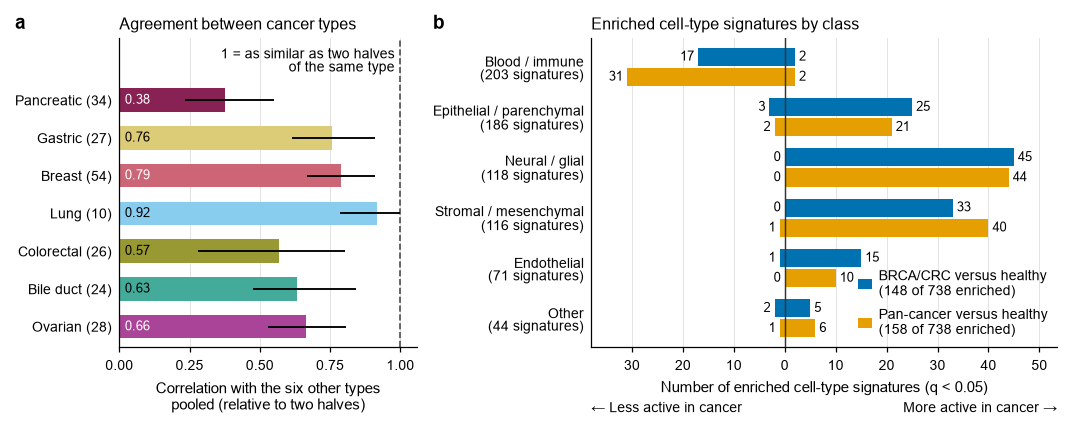

In [4]:
def task_handles(kind="line", labels=None):
    labels = labels or TASK_LABELS
    if kind == "patch":
        return [Patch(facecolor=TASK_COLORS[t], edgecolor="none", label=labels[t]) for t in TASKS]
    if kind == "dot":
        return [Line2D([], [], marker="o", ls="none", color=TASK_COLORS[t], markersize=3.5, label=labels[t]) for t in TASKS]
    return [Line2D([], [], color=TASK_COLORS[t], lw=1.3, label=labels[t]) for t in TASKS]


fig = plt.figure(figsize=fs.size(height=2.75), layout="constrained")
fig.get_layout_engine().set(wspace=0.03, hspace=0.04)
gs = fig.add_gridspec(1, 2, width_ratios=[0.78, 1.22])
axa, axb = (fig.add_subplot(gs[0, i]) for i in range(2))

# --- a: each cancer type against the six other types pooled ----------------------------------
ax = axa
fs.value_grid(ax, axis="x")
yy = np.arange(len(TYPE_ORDER)); vals = np.array([C[t] for t in TYPE_ORDER])
lo = np.array([CI.loc[t, "lo"] for t in TYPE_ORDER]); hi = np.array([CI.loc[t, "hi"] for t in TYPE_ORDER])
XMAX = 1.06
# intervals drawn within 0 to 1 (1 = as similar as two halves of the type); lung has no upper bound, so it runs to 1
bar_cols = [TYPE_COLORS[t] for t in TYPE_ORDER]
ax.barh(yy, vals, height=0.62, color=bar_cols, zorder=2)
ax.hlines(yy, np.clip(lo, 0, 1), np.clip(hi, 0, 1), color="black", lw=0.9, zorder=4)
def _ink(c):   # white on the dark colours, black on the light ones (relative luminance)
    r, g, b = mpl.colors.to_rgb(c)
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else "black"
for y_, v_, c_ in zip(yy, vals, bar_cols):
    ax.text(0.02, y_, num(v_), va="center", ha="left", fontsize=fs.VALUE, color=_ink(c_), zorder=3)
ax.axvline(1, color=fs.NEUTRAL, lw=0.8, ls="--", zorder=1)
ax.text(0.98, -1.05, "1 = as similar as two halves\nof the same type", ha="right", va="center", fontsize=fs.SMALL, linespacing=1.15)
ax.set_yticks(yy); ax.set_yticklabels([f"{TYPE_LABEL[t]} ({N_TYPE[t]})" for t in TYPE_ORDER])
ax.set_ylim(len(TYPE_ORDER) - 0.45, -1.65); ax.set_xlim(0, XMAX); ax.set_xticks(np.arange(0, 1.001, 0.25))
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Correlation with the six other types\npooled (relative to two halves)")
fs.panel(ax, "a", "Agreement between cancer types")

# --- b: cell-type signatures by class --------------------------------------------------------
ax = axb
fs.value_grid(ax, axis="x")
yy = np.arange(len(CLASSES)); h = 0.36
for j, t in enumerate(TASKS):
    y_ = yy + (j - 0.5) * (h + 0.04)
    less = np.array([D[t][k][0] for k in CLASSES]); more = np.array([D[t][k][1] for k in CLASSES])
    ax.barh(y_, -less, height=h, color=TASK_COLORS[t], zorder=2); ax.barh(y_, more, height=h, color=TASK_COLORS[t], zorder=2)
    for yi, a_, b_ in zip(y_, less, more):
        ax.text(-a_ - 0.8, yi, str(a_), ha="right", va="center", fontsize=fs.VALUE)
        ax.text(b_ + 0.8, yi, str(b_), ha="left", va="center", fontsize=fs.VALUE)
ax.axvline(0, color="0.2", lw=0.7, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{k[0].upper() + k[1:]}\n({int(N_CLASS[k])} signatures)" for k in CLASSES], linespacing=1.1)
ax.set_ylim(len(CLASSES) - 0.42, -0.58); ax.tick_params(axis="y", length=0)
ax.set_xlim(-38, 53.5); xt = np.arange(-30, 51, 10); ax.set_xticks(xt); ax.set_xticklabels([str(abs(int(v))) for v in xt])
ax.set_xlabel("Number of enriched cell-type signatures (q < 0.05)")
ax.annotate("← " + LESS[0].upper() + LESS[1:], xy=(0, 0), xycoords="axes fraction", xytext=(0, -26), textcoords="offset points",
            ha="left", va="top", fontsize=fs.SMALL)
ax.annotate(MORE[0].upper() + MORE[1:] + " →", xy=(1, 0), xycoords="axes fraction", xytext=(0, -26), textcoords="offset points",
            ha="right", va="top", fontsize=fs.SMALL)
ax.legend(handles=task_handles("patch", {t: f"{TASK_LABELS[t]}\n({D_TOTAL[t]} of {N_SETS} enriched)" for t in TASKS}),
          loc="lower right", handlelength=1.0, handletextpad=0.5, labelspacing=0.6)
fs.panel(ax, "b", "Enriched cell-type signatures by class")

fs.save(fig, out_path("fig6"))
plt.show()